# Multiband Speech ABR Analysis

Chirp-phase multiband peaky speech, one subject per run. Results are saved to an NPZ file at the end.

In [1]:
import numpy as np
import os
import re
import fnmatch
import mne
import pylab as pl
from scipy.signal import savgol_filter as sg

## Parameters

In [2]:
froot = '/Users/HMB105/Dropbox/Data_Testing/MultibandPeakySpeech/'
# froot = '/Users/HMB105/Library/CloudStorage/Dropbox/Data_Testing/MultibandPeakySpeech/'
fpath = froot + 'EEGdata/'            # BDF files and NPZ pulse files
out_dir = froot + 'Results/'

subj = 'AT'
chan = 'Fz'                           # e.g. 'EXG3', 'Fz'
refchans = ['EXG1', 'EXG2']           # None = no re-referencing
bdf_stem = subj                       # common stem across BDF splits

fs_audio = 48828.125                  # sampling rate of the pulse indices
pad, dur = 0.5, 12.0                  # s of EEG before trigger 2 / after trigger 3; clip length
sets = ['Llo', 'Lmid', 'Lhi', 'Rlo', 'Rmid', 'Rhi']
fake_sets = [f'fake{k}' for k in range(5)]

DROP_TRIALS = [2, 19, 22, 85]         # 0-based (track number - 1); clips with near-duplicate pulses

hp, lp = 150., 2000.                  # causal band-pass on the continuous EEG
delay_ms = 1.6                        # acoustic delay (earphone tubing)

bdfs = fnmatch.filter(os.listdir(fpath), '*' + bdf_stem + '*.bdf')
if len(bdfs) == 0:
    raise RuntimeError(f'No BDF files found for {bdf_stem} in {fpath}')

## Helper functions

In [3]:
def bayesave(x, trialdim=0, timedim=1, smoothtrials=19):
    """Inverse-variance weighted average over trials (used by the trigger-average check)."""
    wts = 1 / np.var(x, axis=timedim, keepdims=True)
    wts = sg(wts, smoothtrials, 3, axis=trialdim)
    norm = wts.sum()
    wts = wts.repeat(x.shape[timedim], axis=timedim)
    return (x * wts).sum(axis=trialdim) / norm


def load_bdf(bdfname, chan, refchans=('EXG1', 'EXG2'), mask=255):
    """Load a BDF, re-reference, and keep only one channel. Only the needed channels are loaded."""
    raw = mne.io.read_raw_bdf(bdfname, preload=False, stim_channel='auto')
    events = mne.find_events(raw, shortest_event=1, mask=mask)   # needs the stim channel, so before picking
    raw.pick([chan] + list(refchans or []))
    raw.load_data()
    if refchans is not None:
        raw.set_eeg_reference(ref_channels=list(refchans))
    raw.pick([chan])
    return raw, events

## Deconvolution

In [4]:
d = np.load(os.path.join(fpath, 'pulse_inds_3band.npz'))
dfake = np.load(os.path.join(fpath, 'fake_pulse_inds.npz'))

### Load, concatenate and causally filter

In [5]:
def split_index(name):     # EEG_Training_HB.bdf -> 0, EEG_Training_HB+001.bdf -> 1, ...
    m = re.search(r'\+(\d+)\.bdf$', name, re.I)
    return int(m.group(1)) if m else 0

loaded = []
for bdf in sorted(bdfs, key=split_index):
    raw, eves = load_bdf(os.path.join(fpath, bdf), chan, refchans=refchans)
    loaded.append((bdf, raw, eves))

fs = loaded[0][1].info['sfreq']
data_list, ev_list, offset = [], [], 0
for bdf, raw, eves in loaded:
    e = eves.copy()
    e[:, 0] += offset - raw.first_samp          # shift events by the samples that came before this file
    data_list.append(raw.get_data()[0])
    ev_list.append(e)
    offset += raw.n_times
    print(f'{bdf}: {raw.n_times / fs / 60:.1f} min | triggers 2/3: {(eves[:, 2] == 2).sum()}/{(eves[:, 2] == 3).sum()}')

eves_all = np.concatenate(ev_list)
data = mne.filter.filter_data(np.concatenate(data_list), fs, hp, lp, method='iir',
                              iir_params=dict(order=1, ftype='butter'),
                              phase='forward', verbose='WARNING')

Extracting BDF parameters from /Users/HMB105/Dropbox/Data_Testing/MultibandPeakySpeech/EEGdata/AT_PeakySpeech.bdf...
Setting channel info structure...
Creating raw.info structure...
Finding events on: Status
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
22454 events found on stim channel Status
Event IDs: [  1   2   3 253]
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Extracting BDF parameters from /Users/HMB105/Dropbox/Data_Testing/MultibandPeakySpeech/EEGdata/AT_PeakySpeech+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
25820 events found on stim channel Status
Event IDs: [1 2 3]
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
EEG channel 

### Check that triggers 2 and 3 alternate (2,3,2,3,...)

In [6]:
seq = eves_all[np.isin(eves_all[:, 2], [2, 3]), 2]
print('first events:', seq[:6], '| last events:', seq[-6:])
print('alternation breaks at event index:', np.where(seq[1:] == seq[:-1])[0])

first events: [2 3 2 3 2 3] | last events: [3 2 3 2 3 2]
alternation breaks at event index: []


## Sanity check: average around the triggers (value = 1) of one band (Lhi)

Using data from preloaded Raw for 90514 events and 657 original time points ...
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  epoch based on EEG : ['Fz']
    Rejecting  ep

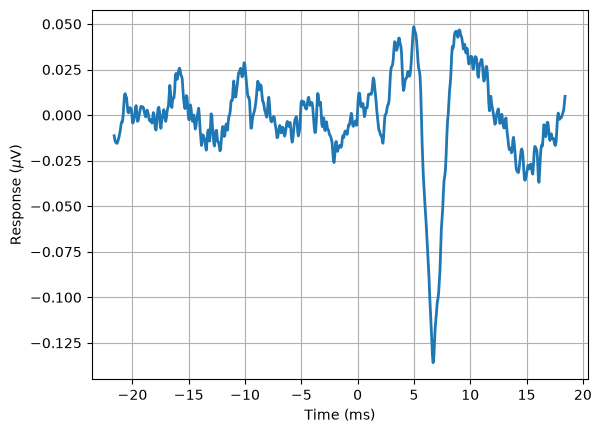

In [7]:
tmin, tmax = -0.02, 0.02
rejthresh = 200e-6

raw_f = mne.io.RawArray(data[None, :], mne.create_info([chan], fs, 'eeg'), verbose='WARNING')
epochs = mne.Epochs(raw_f, eves_all, event_id=[1], tmin=tmin, tmax=tmax, baseline=(tmin, 0.),
                    reject=dict(eeg=rejthresh), verbose='WARNING')

t_tavg = epochs.times * 1e3 - delay_ms                                      # ms
y_tavg = bayesave(epochs.get_data()[:, 0, :], smoothtrials=5) * 1e6         # uV

pl.plot(t_tavg, y_tavg, linewidth=2)
pl.xlabel('Time (ms)'); pl.ylabel(r'Response ($\mu$V)'); pl.grid()

### Slice 13 s chunks using triggers 2 and 3

In [8]:
npad = int(round(pad * fs))
n = int(round((dur + 2 * pad) * fs))

starts = eves_all[eves_all[:, 2] == 2, 0]
ends   = eves_all[eves_all[:, 2] == 3, 0]
starts = starts[:len(ends)]                      # drop the unfinished last trial
eeg = np.array([data[s - npad : s - npad + n] for s in starts])
durs = (ends - starts) / fs
n_trials = len(eeg)
scale = np.median(durs) / dur                    # EEG-vs-audio clock ratio (per-trial values differ by 1 sample at most)

print('eeg shape:', eeg.shape, '| 2->3 duration range (s):', durs.min(), durs.max())

eeg shape: (140, 212992) | 2->3 duration range (s): 11.9998779296875 11.99993896484375


### Regressor

In [9]:
def make_regressor(i, suffix, src=None):
    """Unit-impulse regressor (length n) for trial i (0-based); src is d (bands, default) or dfake."""
    src = d if src is None else src
    p = src[f'track_{i+1:03d}_{suffix}']
    idx = np.round((pad + p / fs_audio * scale) * fs).astype(int)
    x = np.zeros(n)
    x[idx[(idx >= 0) & (idx < n)]] = 1.0
    return x

### Setup

In [10]:
keep = np.ones(n_trials, bool)
keep[DROP_TRIALS] = False
Y_all = np.fft.rfft(eeg, axis=1)
eeg_var = eeg.var(axis=1)
lags = (np.arange(n) - n // 2) / fs         # s; lag 0 is at index n//2 after fftshift
t_axis = lags * 1e3 - delay_ms              # ms, delay-corrected

def crop_ms(w, t0_ms, t1_ms):
    """Crop a full response to [t0_ms, t1_ms] on the delay-corrected axis. Returns (t in ms, response in uV)."""
    m = (t_axis >= t0_ms) & (t_axis <= t1_ms)
    return t_axis[m], w[m] * 1e6

# SNR (Polonenko & Eisenreich, 2026)
snr_win_ms = (0., 9.)
noise_range_ms = (-480., -20.)
win_len = snr_win_ms[1] - snr_win_ms[0]
noise_starts = np.arange(noise_range_ms[0], noise_range_ms[1] - win_len + 1e-9, win_len)
cm = (t_axis >= noise_range_ms[0]) & (t_axis < snr_win_ms[1])
t_crop = t_axis[cm]

# Trial counts for the SNR-vs-trials curve
n_keep = int(keep.sum())
n_checks, min_trials = 150, 10
ks = np.unique(np.linspace(min(min_trials, n_keep), n_keep, n_checks).round().astype(int))

def deconv_all(suffix, src):
    """One pass over the kept trials, inverse-variance weighted.
    Returns (full, crops): full = circular response (V) from all kept trials,
    crops[k] = cropped response (uV) from the first k kept trials, for k in ks."""
    idxs = np.flatnonzero(keep)
    num = np.zeros(n // 2 + 1, dtype=complex)
    den = np.zeros(n // 2 + 1)
    sw, crops, full = 0.0, {}, None
    for j, i in enumerate(idxs, start=1):
        X = np.fft.rfft(make_regressor(i, suffix, src))
        wi = 1 / eeg_var[i]
        num += wi * np.conj(X) * Y_all[i]
        den += np.abs(X) ** 2
        sw += wi
        if j in ks:
            w = np.fft.fftshift(np.fft.irfft((num / sw) / (den / j), n))
            crops[j] = w[cm] * 1e6
            if j == len(idxs):
                full = w
    return full, crops

def snr_from_crop(w):
    """SNR (dB) of a cropped response in uV."""
    def wvar(t0, t1):
        m = (t_crop >= t0) & (t_crop < t1)
        return w[m].var()
    var_sn = wvar(*snr_win_ms)
    var_n = np.mean([wvar(s0, s0 + win_len) for s0 in noise_starts])
    ratio = (var_sn - var_n) / var_n
    return 10 * np.log10(ratio) if ratio > 0 else np.nan

### Deconvolve all band sets and the fake pulse trains

In [11]:
full, cum, full_fake, cum_fake = {}, {}, {}, {}
for s in sets:
    full[s], cum[s] = deconv_all(s, d)
for s in fake_sets:
    full_fake[s], cum_fake[s] = deconv_all(s, dfake)
common = np.mean([full_fake[s] for s in fake_sets], axis=0)

### Common component

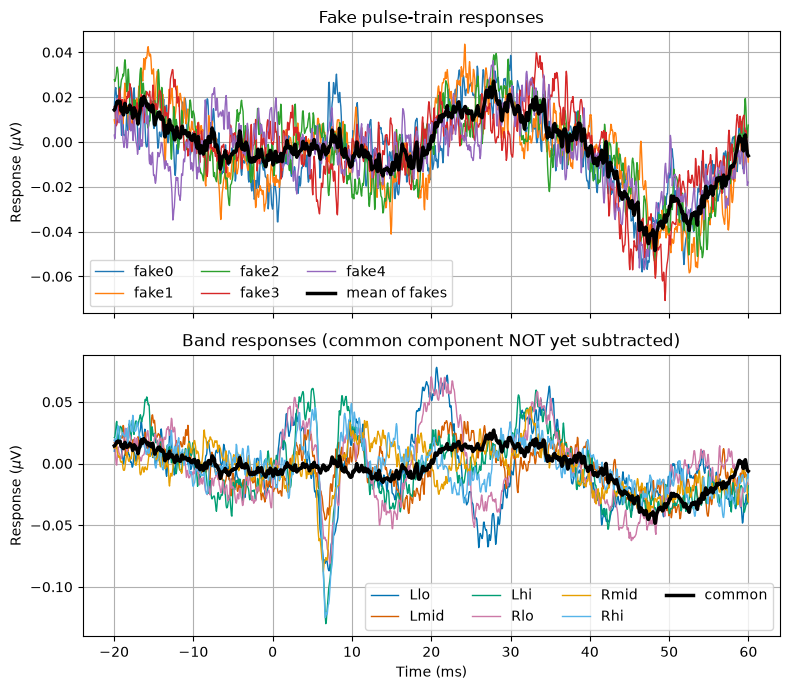

In [12]:
colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
fig, ax = pl.subplots(2, 1, figsize=(8, 7), sharex=True)
for s in fake_sets:
    t, y = crop_ms(full_fake[s], -20, 60)
    ax[0].plot(t, y, lw=1, label=s)
_, yc = crop_ms(common, -20, 60)
ax[0].plot(t, yc, 'k', lw=2.5, label='mean of fakes')
ax[0].set_title('Fake pulse-train responses'); ax[0].legend(ncol=3); ax[0].grid()

for s, col in zip(sets, colors):
    t, y = crop_ms(full[s], -20, 60)
    ax[1].plot(t, y, lw=1, color=col, label=s)
ax[1].plot(t, yc, 'k', lw=2.5, label='common')
ax[1].set_title('Band responses (common component NOT yet subtracted)'); ax[1].legend(ncol=4); ax[1].grid()
ax[1].set_xlabel('Time (ms)')
for a in ax:
    a.set_ylabel(r'Response ($\mu$V)')
pl.tight_layout()

## Band responses, common component subtracted (Left = blue, Right = red)

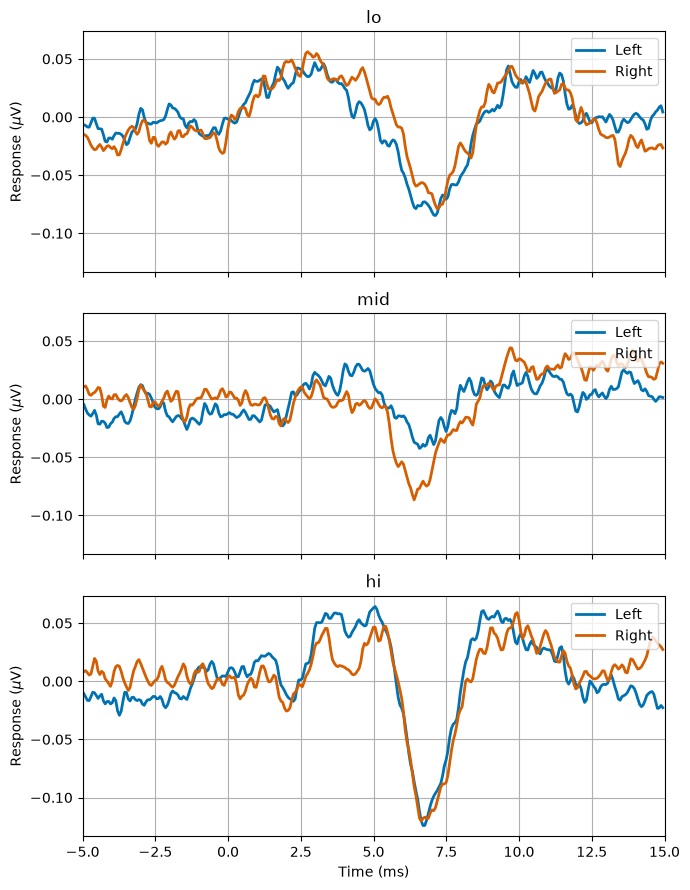

In [13]:
plot_win = (-5, 15)      # ms, delay-corrected axis
blue, red = '#0072B2', '#D55E00'
bands = ['lo', 'mid', 'hi']

band_resp = {s: full[s] - common for s in sets}     # full responses (V)

fig, axs = pl.subplots(3, 1, figsize=(7, 9), sharex=True, sharey=True)
for ax, b in zip(axs, bands):
    for ear, col, lab in [('L', blue, 'Left'), ('R', red, 'Right')]:
        ax.plot(*crop_ms(band_resp[ear + b], *plot_win), color=col, lw=2, label=lab)
    ax.set_title(b); ax.grid(); ax.legend(loc='upper right')
    ax.set_ylabel(r'Response ($\mu$V)')
axs[-1].set_xlabel('Time (ms)')
axs[-1].set_xlim(*plot_win)
pl.tight_layout()

## Response SNR vs. number of trials

SNR (dB) = 10 log10((var(S+N) - var(N)) / var(N)); signal window 0-9 ms, noise from 9 ms segments between -480 and -20 ms. SNR60 is the SNR standardized to 1 minute; t to 0 dB = 60 x 10^(-SNR60/10) s.

At 136 trials (27.2 min):
set     SNR (dB)    SNR60  t to 0 dB (min)
Llo        10.46    -3.89              2.4
Lmid        2.52   -11.82             15.2
Lhi        13.89    -0.45              1.1
Rlo        10.19    -4.16              2.6
Rmid        6.54    -7.81              6.0
Rhi        11.52    -2.82              1.9


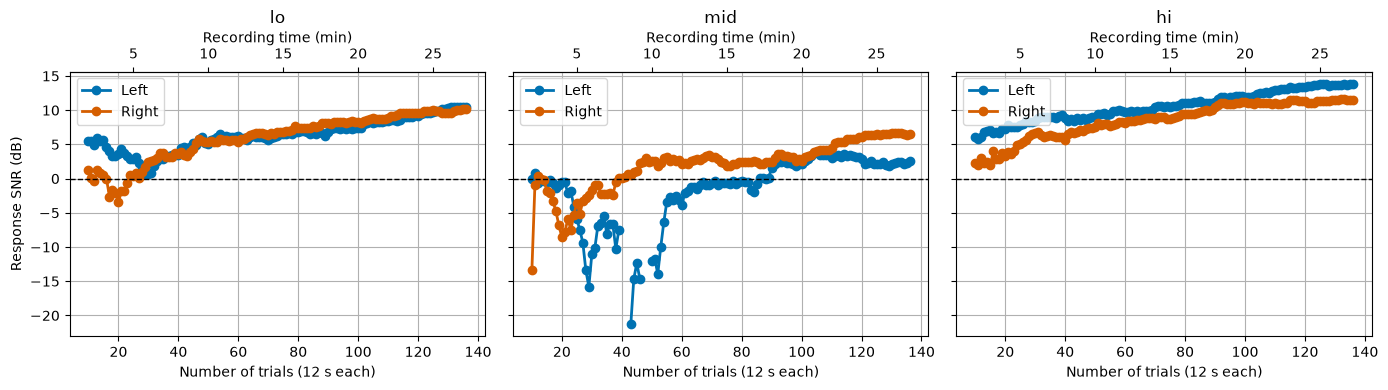

In [14]:
common_k = {k: np.mean([cum_fake[f][k] for f in fake_sets], axis=0) for k in ks}
snr_k = {s: np.array([snr_from_crop(cum[s][k] - common_k[k]) for k in ks]) for s in sets}

fig, axs = pl.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, b in zip(axs, bands):
    for ear, col, lab in [('L', blue, 'Left'), ('R', red, 'Right')]:
        ax.plot(ks, snr_k[ear + b], 'o-', color=col, lw=2, label=lab)
    ax.axhline(0, color='k', lw=1, ls='--')
    ax.set_title(b); ax.set_xlabel('Number of trials (12 s each)'); ax.grid(); ax.legend(loc='upper left')
    sec = ax.secondary_xaxis('top', functions=(lambda k: k * dur / 60, lambda m: m * 60 / dur))
    sec.set_xlabel('Recording time (min)')
axs[0].set_ylabel('Response SNR (dB)')
pl.tight_layout()

print(f'At {ks[-1]} trials ({ks[-1] * dur / 60:.1f} min):')
print(f'{"set":6s} {"SNR (dB)":>9s} {"SNR60":>8s} {"t to 0 dB (min)":>16s}')
for s in sets:
    snr60 = snr_k[s][-1] + 10 * np.log10(60 / (ks[-1] * dur))
    print(f'{s:6s} {snr_k[s][-1]:9.2f} {snr60:8.2f} {60 * 10 ** (-snr60 / 10) / 60:16.1f}')

## Broadband chirp ABR (sum of bands)

total SNR (dB): {'L': 12.69, 'R': 12.93}


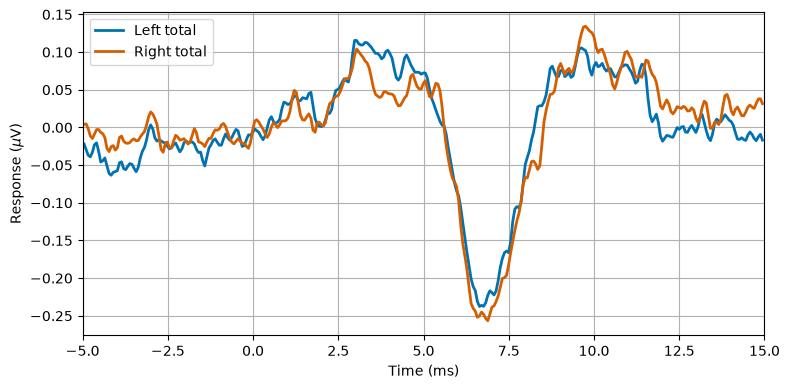

In [15]:
tot = {ear: sum(band_resp[ear + b] for b in bands) for ear in 'LR'}

fig, ax = pl.subplots(figsize=(8, 4))
for ear, col, lab in [('L', blue, 'Left total'), ('R', red, 'Right total')]:
    ax.plot(*crop_ms(tot[ear], *plot_win), color=col, lw=2, label=lab)
ax.set_xlabel('Time (ms)'); ax.set_ylabel(r'Response ($\mu$V)')
ax.set_xlim(*plot_win); ax.grid(); ax.legend()
pl.tight_layout()

print('total SNR (dB):', {e: round(float(snr_from_crop(tot[e][cm] * 1e6)), 2) for e in 'LR'})

## Compare the trigger-based average with the deconvolved Lhi

r = 0.97 over 0-15 ms


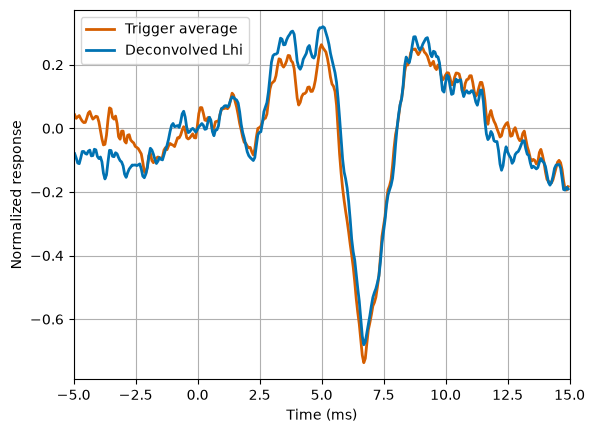

In [16]:
cmp_win = (0., 15.)     # ms, normalization and correlation window

lhi = np.interp(t_tavg, t_axis, full['Lhi'] * 1e6)    # with the common component, as the trigger average has it

pw = (t_tavg >= plot_win[0]) & (t_tavg <= plot_win[1])
m = (t_tavg >= cmp_win[0]) & (t_tavg <= cmp_win[1])

for lab, y, col in [('Trigger average', y_tavg, '#D55E00'), ('Deconvolved Lhi', lhi, '#0072B2')]:
    pl.plot(t_tavg[pw], (y / np.ptp(y[m]))[pw], color=col, lw=2, label=lab)
pl.xlabel('Time (ms)'); pl.ylabel('Normalized response'); pl.xlim(*plot_win); pl.grid(); pl.legend()

print(f'r = {np.corrcoef(y_tavg[m], lhi[m])[0, 1]:.2f} over {cmp_win[0]:.0f}-{cmp_win[1]:.0f} ms')

## Save results

`resp`: common-component-subtracted response for each of `sets` (uV); `resp_raw`: before subtraction.

In [17]:
save_win = (-10., 20.)      # ms
os.makedirs(out_dir, exist_ok=True)

t_save, _ = crop_ms(np.zeros(n), *save_win)
resp     = np.array([crop_ms(band_resp[s], *save_win)[1] for s in sets])
resp_raw = np.array([crop_ms(full[s], *save_win)[1] for s in sets])
common_s = crop_ms(common, *save_win)[1]
total_L, total_R = (crop_ms(tot[e], *save_win)[1] for e in 'LR')

snr_db     = np.array([snr_from_crop(band_resp[s][cm] * 1e6) for s in sets])
snr_db_raw = np.array([snr_from_crop(full[s][cm] * 1e6) for s in sets])
snr_total  = np.array([snr_from_crop(tot[e][cm] * 1e6) for e in 'LR'])

out_file = os.path.join(out_dir, f'{subj}_MultibandABR.npz')
np.savez(out_file,
         subj=subj, chan=chan, sets=np.array(sets), bands=np.array(bands),
         t_ms=t_save, resp=resp, resp_raw=resp_raw, common=common_s,
         total_L=total_L, total_R=total_R,
         snr_db=snr_db, snr_db_raw=snr_db_raw, snr_total_LR=snr_total,
         ks=ks, snr_vs_trials=np.array([snr_k[s] for s in sets]),
         keep=keep, dropped_trials=np.flatnonzero(~keep), n_trials_used=n_keep, dur=dur,
         fs=fs, hp=hp, lp=lp, delay_ms=delay_ms, bdfs=np.array([t[0] for t in loaded]))
print('saved', out_file)

saved /Users/HMB105/Dropbox/Data_Testing/MultibandPeakySpeech/Results/AT_MultibandABR.npz
